In [62]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [63]:
# Load the files into a Pandas Dataframe
train = pd.read_csv('Train.csv')

In [64]:
train.head()

,DATE,TRANSACTION DETAILS,Account_NO,CHQ.NO.,WITHDRAWAL AMT,DEPOSIT AMT,BALANCE AMT,Category
0,2014-02-28,NEFT/FDRL401249529/INDIAFORENSIC,84903292,NaN,0.0,15000000.0,15000000.0,Money-Transfer
1,2014-02-28,NEFT/FDRL401249532/INDIAFORENSIC,84903292,NaN,0.0,15000000.0,60000000.0,Money-Transfer
2,2014-02-28,NEFT/FDRL401249534/INDIAFORENSIC,84903292,NaN,0.0,15000000.0,90000000.0,Money-Transfer
3,2014-02-28,NEFT/FDRL401249590/INDIAFORENSIC,84903292,NaN,0.0,10000000.0,100000000.0,Money-Transfer
4,2014-02-28,NEFT/FDRL401249531/INDIAFORENSIC,84903292,NaN,0.0,15000000.0,45000000.0,Money-Transfer


In [65]:
print(train.shape)

(57974, 8)


<AxesSubplot:>

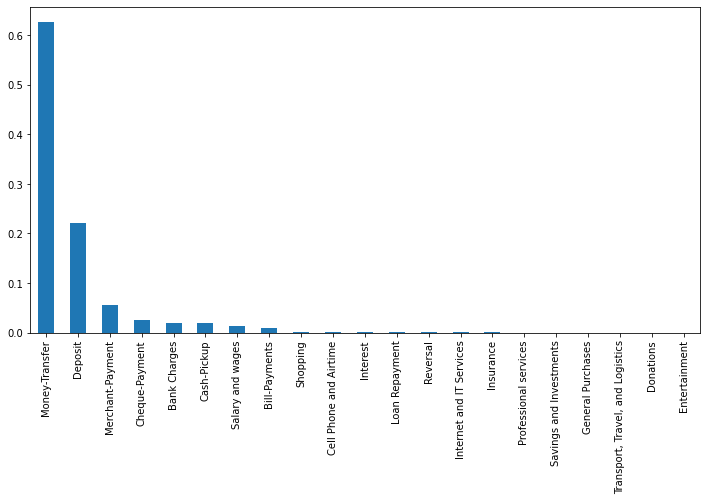

In [66]:
plt.figure(figsize=(12,6))
train.Category.value_counts(normalize=True).plot.bar()

In [67]:
dico={
    "cat_1":["NEFT", "RTGS", "IMPS", "RMCPL"],
    "cat_2":["CASHDEP", "ICA17825"],
    "cat_3":["POSACQ", "SETT", "CHQDEPOSITRETURN"],
    "cat_4":["CHQDEP/OWDEL1"],
    "cat_5":["AEPS/TAX", "AEPS/FEES", "MICRO", "CHARGES"],
    "cat_6":["BEAT", "DSB"],
    "cat_7":["INCOME"],
    "cat_8":["BBPSDT", "BBPSSE"],
    "cat_9":["NAAPTOLONLINESHOPPINGP", "STAMPPAPERPURCHASING", "PAYMENTSFOR"],
    "cat_10":["VODAFONE", "AIRTEL"],
    "cat_11":["INT.COLL"],
    "cat_12":["LOANRECOVERYFOR"],
    "cat_13":["REV", "IWCHQRETURN"],
    "cat_14":["TIMESINTERNETLIMITED"],
    "cat_15":["INSURANCE"],
    "cat_16":["RAIASSOCIATES"],
    "cat_17":["BOOKING"],
    "cat_18":["NETHOPE"],
}

In [68]:
def mapping(x):
    for i in dico.keys():
        for j in dico[i]:
            y=j.split("/")
            if len(y)==2:
                if ((y[0] in x)+(y[1] in x))==2:
                    return i
            if len(y)==1:
                if y[0] in x:
                    return i
          
    return x

In [69]:
def modif(df):
    df["Account_NO"]=df["Account_NO"].map(str)
    df["year"]=df.DATE.map(lambda x: x.split("-")[0])
    df["month"]=df.DATE.map(lambda x: x.split("-")[1])
    df["var_1"]=df["TRANSACTION DETAILS"].map(mapping)
    df.drop(["DATE","month","TRANSACTION DETAILS"],axis=1, inplace=True)
    if "ID" in df.columns:
        df.drop(["ID","CHQ.NO."],axis=1, inplace=True)
    return df

In [70]:
# Filter dataset
train = train[train.Category.notnull()]
train.drop("CHQ.NO.",axis=1, inplace=True)
train.dropna(axis=0,inplace=True)

In [71]:
# Feature Engenireering
train=modif(train)

val_columns=[i for i in train.Category.unique() if (train.Category[train.Category==i].shape[0]/train.shape[0])>0.001]
train=train[train.Category.isin(val_columns)]

In [72]:
def encodage(df):
    return df

In [73]:
def pre_processing(df):

    #df=imputation(df)
    df=encodage(df)

    if "Category" in df.columns.values:
        X = df.drop("Category", axis=1)
        y = df.Category
        return X,y
    else:
        X = df
        return X 

## Modeling

In [74]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.feature_extraction.text import HashingVectorizer,TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier, ElasticNet, Lasso, RidgeClassifier
from sklearn.neural_network import MLPClassifier

In [75]:
train_df, test_df= train_test_split(train, random_state=25, test_size=0.6)

In [76]:
X_train, y_train = pre_processing(train_df)
X_test, y_test = pre_processing(test_df)

In [77]:
def make_model(df):
    numerical_features=df.select_dtypes(["float","int"]).columns
    categorical_features=df.select_dtypes("object").columns

    numerical_pipeline=make_pipeline(SimpleImputer(), StandardScaler())
    categorical_pipeline=make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown='ignore'))

    process=make_column_transformer((numerical_pipeline, numerical_features), (categorical_pipeline, categorical_features))

    #model=make_pipeline(process, DecisionTreeClassifier(random_state=0))
    #model=make_pipeline(process, RandomForestClassifier(random_state=0))
    model=make_pipeline(process, MLPClassifier(random_state=0))
    return model

In [78]:
model = make_model(X_train)

In [79]:
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score, log_loss
from sklearn.model_selection import learning_curve

In [80]:
def evaluation(model):

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(classification_report(y_test, y_pred))
    proba=model.predict_proba(X_test)
    print(f"Log_loss:{log_loss(y_test, proba)}")

    # N, train_score, val_score = learning_curve(
    #                                 model, X_train, y_train, cv=4,
    #                                 scoring='f1_micro',
    #                                 train_sizes=np.linspace(0.1,1,10)
    #                             )
    
    # plt.figure(figsize=(12,8))
    # plt.plot(N, train_score.mean(axis=1), label='train score')
    # plt.plot(N, val_score.mean(axis=1), label="validation score")
    # plt.legend()

In [81]:
evaluation(model)

                        precision    recall  f1-score   support

          Bank Charges       1.00      0.76      0.86       672
         Bill-Payments       1.00      1.00      1.00       284
           Cash-Pickup       1.00      1.00      1.00       653
Cell Phone and Airtime       1.00      1.00      1.00        69
        Cheque-Payment       0.98      0.95      0.97       866
               Deposit       1.00      1.00      1.00      7463
              Interest       1.00      1.00      1.00        50
        Loan Repayment       1.00      1.00      1.00        36
      Merchant-Payment       1.00      0.91      0.95      1885
        Money-Transfer       0.98      1.00      0.99     20122
              Reversal       0.93      0.76      0.84        37
      Salary and wages       1.00      1.00      1.00       479
              Shopping       1.00      0.91      0.96        70

              accuracy                           0.99     32686
             macro avg       0.99     

In [82]:
#print(model._final_estimator.feature_importances_)

In [83]:
# Feature Engenireering
test=pd.read_csv("Test.csv")
test=modif(test)

prediction=pd.DataFrame(model.predict_proba(test),columns=sorted(val_columns))

In [84]:
ss = pd.read_csv("SampleSubmission.csv")

for column in prediction.columns:
    ss[column]=prediction[column]

ss.head()

,ID,Bank Charges,Bill-Payments,Cash-Pickup,Cell Phone and Airtime,Cheque-Payment,Deposit,Donations,General Purchases,Insurance,...,Internet and IT Services,Loan Repayment,Merchant-Payment,Money-Transfer,Professional services,Reversal,Salary and wages,Savings and Investments,Shopping,"Transport, Travel, and Logistics"
0,2014-02-28 00:00:00X3000000000,8.996096e-10,1.151018e-08,3.122660e-06,2.596448e-07,5.970204e-06,1.648379e-06,0,0,0,...,0,3.887494e-07,1.995948e-08,0.991651,0,0.008335,1.005090e-06,0,1.627589e-08,0
1,2014-02-28 00:00:00X7500000000,8.992125e-10,1.152326e-08,3.128013e-06,2.598079e-07,5.977693e-06,1.646520e-06,0,0,0,...,0,3.900826e-07,1.989976e-08,0.991609,0,0.008377,1.006427e-06,0,1.629032e-08,0
2,2014-03-08 00:00:00X4500002863,2.136923e-05,7.844434e-09,1.795173e-08,4.929800e-09,2.570664e-09,4.628190e-09,0,0,0,...,0,5.201203e-09,2.452265e-10,0.999967,0,0.000011,9.179595e-07,0,7.909439e-10,0
3,2014-03-08 00:00:00X6000002863,1.460260e-06,1.431856e-09,4.761488e-09,1.037104e-09,5.071197e-10,3.129773e-10,0,0,0,...,0,7.768391e-09,8.953501e-11,0.999996,0,0.000002,4.166239e-08,0,2.594696e-10,0
4,2014-03-08 00:00:00X6000005726,2.132686e-05,7.840031e-09,1.794420e-08,4.926490e-09,2.569373e-09,4.623485e-09,0,0,0,...,0,5.204346e-09,2.447145e-10,0.999967,0,0.000011,9.179565e-07,0,7.907803e-10,0


In [ ]:
ss.to_csv("submission_43.csv", index=False)